##### Command de instaler libs :
- pip install numpy matplotlib seaborn scikit-learn opencv-python kaggle
- mlflow

In [ ]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import cv2

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import f1_score

import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GlobalAveragePooling2D, Dropout, Dense
from tensorflow.keras.callbacks import ModelCheckpoint, BackupAndRestore, EarlyStopping
from tensorflow.keras.utils import to_categorical
import mlflow
import kagglehub

RANDOM_KEY=26
SIZE_IMAGE=224
BATCH_SIZE = 45
EPOCHS = 10
AUTOTUNE = tf.data.AUTOTUNE

DATA_DIR = Path(kagglehub.dataset_download("hamzahajjaji/brief-5-dataset") + '/Data')
print(DATA_DIR)

Mounting files to /kaggle/input/datasets/hamzahajjaji/brief-5-dataset...


#### Charger les images

In [ ]:
def loead_images(data_dire:str):
    images = []
    labels = []

    extention_allow = {".jpeg", ".jpg", ".bmp", ".png"}

    for folder in Path(data_dire).iterdir():
        if not folder.is_dir():
            continue

        label = folder.name

        for file in folder.iterdir():
            if file.suffix.lower() not in extention_allow:
                continue

            images.append(str(file))
            labels.append(label)
    return images, labels

images_path, labels = loead_images(DATA_DIR)


print("Nomber d'images :", len(images_path))
print("Nomber de labels :", len(labels))

print('Example de image:', images_path[0])
print('Example de Label:', labels[0])

ModuleNotFoundError: No module named 'src'

#### Convertir les listes en tableaux NumPy

In [ ]:
def convert_to_numpay_table(images, labels):
    return np.array(images), np.array(labels)

X, y = convert_to_numpay_table(images_path, labels)

#### Afficher un échantillon d'images

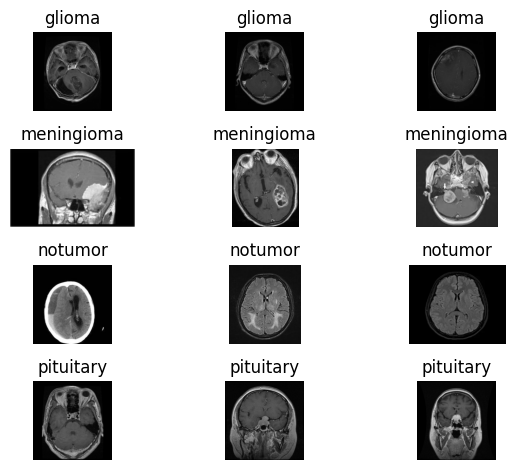

In [ ]:
def afficher_images_echntillon(images, labels):
    classes = np.unique(labels)
    _, axes = plt.subplots(len(classes), 3)

    for i, classe in enumerate(classes):
        images_index = np.where(labels == classe)[0][:3]
        for j, index in enumerate(images_index):
            # loead et converter BGR to RGB
            image = cv2.cvtColor(cv2.imread(images[index]), cv2.COLOR_BGR2RGB)
            axes[i, j].imshow(image)
            axes[i, j].set_title(classe)
            axes[i, j].axis('off')
    plt.tight_layout()
    plt.show()

classes = np.unique(y)

afficher_images_echntillon(X, y)

#### Afficher la distribution et l'équilibre des images

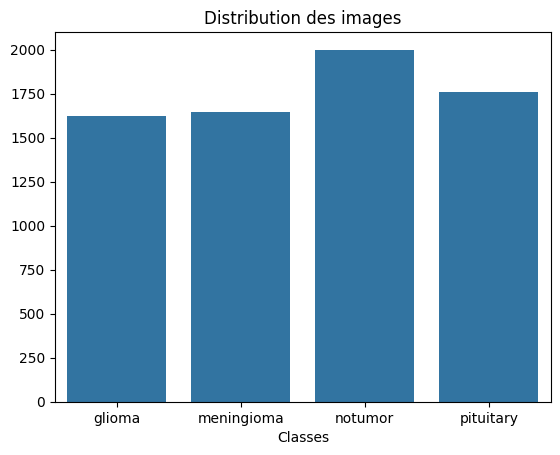

In [ ]:
def afficher_distribution_classes(labels):
    classes, counts = np.unique(labels, return_counts=True)
    plt.figure()
    sns.barplot(x=classes, y=counts)
    plt.title('Distribution des images')
    plt.xlabel('Classes')
    plt.show()

afficher_distribution_classes(y)

#### Appliquer Label Encoging 

In [ ]:
def applay_encoding(list):
    encoder = LabelEncoder()
    return encoder.fit_transform(list), encoder

y_encoder, label_encoder = applay_encoding(y)

num_classes = len(np.unique(y_encoder))

print(num_classes)

4


#### Split data

In [ ]:
# Split test and train
X_temp, X_test, y_temp, y_test = train_test_split(
    X,
    y_encoder, 
    test_size=0.3,
    stratify=y_encoder,
    random_state=RANDOM_KEY
)

# Split validation
X_train, X_val, y_train, y_val = train_test_split(
    X_temp,
    y_temp,
    test_size=0.2,
    stratify=y_temp,
    random_state=RANDOM_KEY
)

print("Train :", len(X_train))
print("Validation :", len(X_val))
print("Test :", len(X_test))

Train : 3932
Validation : 984
Test : 2107


#### Appliquer One-Hot Encoding

In [ ]:
y_train = to_categorical(y_train, num_classes=num_classes)
y_val = to_categorical(y_val, num_classes=num_classes)
y_test = to_categorical(y_test, num_classes=num_classes)

#### Data augmentation

In [ ]:
data_augmentation = tf.keras.Sequential([
    layers.RandomRotation(0.03),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(
        height_factor=0.05,
        width_factor=0.05
    )
])

#### Exemple des images avec augmentation

In [ ]:
def afficher_images_augmentation(image_path):
    # Loader l'image avec OpenCV et converter à RGB
    image = cv2.imread(image_path)

    if image is None:
        print(f"Erreur de chargement : {image_path}")
        return
    
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image = cv2.resize(image, (SIZE_IMAGE, SIZE_IMAGE))

    # 2. Ajouter batch dimension pour keras (1, H, W, C)
    image_batch = tf.cast(image, tf.float32)
    image_batch = tf.expand_dims(image_batch, axis=0)

    # Appliquer l'augmentation
    image_augmentee_batch = data_augmentation(image_batch, training=True)

    # Supprimer dimension et converter à uint8 pour afficher avec Matplotlib
    image_augmentee = tf.squeeze(image_augmentee_batch, axis=0)
    image_augmentee = tf.clip_by_value(image_augmentee, 0, 255)
    image_augmentee = image_augmentee.numpy().astype("uint8")

    # Affichage
    plt.figure(figsize=(8, 4))
    
    plt.subplot(1, 2, 1)
    plt.imshow(image)
    plt.title("Image Normale")
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(image_augmentee)
    plt.title("Image Augmentée")
    plt.axis('off')

    plt.tight_layout()
    plt.show()

for i in range(3):
    afficher_images_augmentation(X_train[i])

ValueError: Tensor's shape (1, 224, 224, 3) is not compatible with supplied shape (224, 224, 3).

#### TensorFlow Dataset

In [ ]:
# Create dataset avec params
def create_dataset(x_data, y_data, normalize_collback, is_use_shuffle = False):
    dataset = (
        tf.data.Dataset
            .from_tensor_slices((x_data, y_data))
            .map(
                lambda image_path, label: load_image(image_path, label, normalize_collback),
                num_parallel_calls=AUTOTUNE
            )
    )

    # Shuffle les donnes
    if is_use_shuffle:
        dataset.shuffle(
            buffer_size=len(x_data), # pour utiliser tout les donnes dans mélange
            seed=RANDOM_KEY # Randomize logic
        )

    return dataset.batch(BATCH_SIZE).prefetch(AUTOTUNE) # Pour preparer les batch en paralille


# Load image and resize and normalize
def load_image(filename, label, normalize_collback):
    # load image
    raw = tf.io.read_file(filename)

    # converter image à matric de tensors avec 3 channels
    image = tf.image.decode_image(raw, channels=3)
    image.set_shape([None, None, 3]) # Déclarer le size image pour éviter error
    
    # Resize
    image = tf.image.resize(image, [SIZE_IMAGE, SIZE_IMAGE])

    # Normalization pour Base model
    image  = normalize_collback(image)
    return image, label

#### Visualiser les courbes d'apprentissage

In [ ]:
def afficher_courbes_apprentissage(history):
    # Accuracy
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.plot(history["accuracy"], label="Accuracy - Train")
    plt.plot(history["val_accuracy"], label="Accuracy - Validation")

    plt.title("Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()

    # Loss
    plt.subplot(1, 2, 2)
    plt.plot(history["loss"], label="Loss - Train")
    plt.plot(history["val_loss"], label="Loss - Validation")

    plt.title("Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()

    plt.tight_layout()
    plt.show()

#### Evaluate model

In [ ]:
def evaluate_model(model, test_ds, model_path ,y_test, name):
    # Predire les probabilites sur le dataset de test
    y_pred_probs = model.predict(test_ds, verbose=0) # Probabiliter sur les 4 classes
    # print(y_pred_probs[0])

    # Recuperer la classe avec la probabilite maximale
    y_pred = np.argmax(y_pred_probs, axis=1) # index de max proba sur les column 

    # Convertir les labels one-hot en numeros de classes
    y_true = np.argmax(y_test, axis=1) # convert One hot encoding à label encoded

    # Evaluer sur le dataset de test
    test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)

    f1 = f1_score(y_true, y_pred, average='macro')

    # Enregistrer les metriques dans MLflow
    mlflow.log_metric("test_loss", float(test_loss))
    mlflow.log_metric("test_accuracy", float(test_accuracy))
    mlflow.log_metric("test_f1_score", float(f1))

    print(
        f"Resultats : Loss={test_loss:.4f} | "
        f"Accuracy={test_accuracy:.4f} | "
        f"F1-score={f1:.4f}"
    )

    # ================= MATRICE DE CONFUSION =================
    classes = label_encoder.classes_

    cm = confusion_matrix(
        y_true, 
        y_pred,
        labels=np.arange(len(classes))
    )

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=classes
    )

    display.plot(cmap="Blues", xticks_rotation=45)
    plt.title("Matrice de confusion")
    plt.tight_layout()
    plt.show()

    # Sauvegarder l'image
    cm_path = f"{model_path}/confusion_matrix.png"
    plt.savefig(cm_path, dpi=300, bbox_inches="tight")

    # Enregistrer dans MLflow comme artifact
    mlflow.log_artifact(cm_path, artifact_path="evaluation")

    # ================= RAPPORT DE CLASSIFICATION =================
    # Generer le rapport
    report = classification_report(
        y_true,
        y_pred,
        labels=np.arange(len(classes)),
        target_names=classes,
        zero_division=0
    )

    print(report)

    # Sauvegarder le rapport dans un fichier TXT
    report_path = f"{model_path}/classification_report.txt"

    with open(report_path, "w", encoding="utf-8") as file:
        file.write(report)

    # Enregistrer dans MLflow comme artifact
    mlflow.log_artifact(
        report_path,
        artifact_path="evaluation"
    )

    # ================= ENREGISTREMENT MLFLOW =================
    mlflow.tensorflow.log_model(
        model=model,
        artifact_path="model",
        registered_model_name=name
    )


In [ ]:
def build_transfer_model(base_model, normalize_collback, x_train, y_train, x_val, y_val, x_test,y_test):
    # Charger le modele pre-entraine
    base = base_model(
        weights='imagenet', # loader les weights of train imagenet
        include_top=False, # remove classes of predicts base
        input_shape=(SIZE_IMAGE, SIZE_IMAGE, 3) # Size of input
    )

    # ================= DATASETS =================
    # Trian
    train_ds = create_dataset(x_train, y_train, normalize_collback= normalize_collback, is_use_shuffle=True)

    # Validation 
    val_ds = create_dataset(x_val, y_val, normalize_collback)

    # Test
    test_ds = create_dataset(x_test, y_test, normalize_collback)

    # ================= DOSSIER =================
    model_path = f"models/{base.name}"
    Path(model_path).mkdir(parents=True, exist_ok=True)

    # ================= TRANSFER LEARNING (Inference) =================
    
    base.trainable = False # franze all parametres of base model to not chnager on training

    # Architecture Sequential
    model = Sequential([
        base, # Extraire les caractéristiques en mode inference

        # Appliquer augmentation
        data_augmentation,

        GlobalAveragePooling2D(), # minimizer les Featurs Map à vectore 

        # hiden layer
        Dense(128, activation="relu"),
        Dropout(0.3),

        # Output layer
        Dense(4, activation="softmax")
    ])

    model.summary()

    # Compilation du modele
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), # Optimizer avec learninig rate
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    # Callbacks du Transfer Learning
    callbacks_tl = [
        # Suvgarder le baset model pendant le training
        ModelCheckpoint(
            filepath=f"{model_path}/best_model_tl.keras", # path de bast model
            monitor="val_loss", # monitore de comparisent
            save_best_only=True, # Sauvgarder le baset model sulment
            mode="min", # Suavgarder le model de min monitor
            verbose=1 # afficher sur terminal
        ),
        # Sauvgarder le étap de train si ariter pour pas perdet le étap de training
        BackupAndRestore(
            backup_dir=f"{model_path}/backup_tl" # dosser de sauvgarder
        ),
        # Limiter le surapprentissage
        EarlyStopping(
            monitor="val_loss", # monitore de comparisent
            patience=5, # nomber des epochs sans augmentation de monitor
            restore_best_weights=True, # returner baset weights
            mode="min", # minimuent monitor
            verbose=1
        )
    ]

    # ================= RUN 1 : TRANSFER LEARNING =================

    with mlflow.start_run(run_name=f"{base.name}_feature_extraction"):
        
        mlflow.set_tag("training_stage", "transfer_learning")

        mlflow.log_params({
            "base_model": base.name,
            "batch_size": BATCH_SIZE,
            "epochs": EPOCHS,
            "image_size": SIZE_IMAGE,
            "learning_rate": 0.001,
        })

        print('\n========= Tresfer Learning =========\n')

        # Entrainement du Transfer Learning
        start_time = time.time()

        trensfoer_history = model.fit(
            train_ds,
            validation_data=val_ds,
            epochs=EPOCHS,
            callbacks=callbacks_tl
        )

        train_time = time.time() - start_time

        # Enregistrer les mtrics
        mlflow.log_metric("training_duration_TL_seconds", train_time)

        print(f"Temps d'entraînement en Trensfor learning : {train_time / 60:.2f} minute")

        # ================= EVALUATION =================
        evaluate_model(model, test_ds, model_path, y_test, base.name)

        # ================= COURBES =================
        afficher_courbes_apprentissage(trensfoer_history.history)

    # ================= FINE-TUNING (Training) =================
    
    # Autoriser l'entrainement des couches du modele de base
    base.trainable = True

    # Frazer tout les layers de 0 jusqua dérnier 30 layers
    for layer in base.layers[:-30]:
        layer.trainable = False

    # Rester les 30 derniéres couches au mode inference si est instence à BatchNormalization
    # Garder BatchNormalization non entrainable
    for layer in base.layers[-30:]:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False

    # Recompiler apres la modification de trainable
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001), # Optimizer avec learninig rate tres petit
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    # Callbacks du Fine-Tuning
    callbacks_ft = [
        ModelCheckpoint(
            filepath=f"{model_path}/best_model_ft.keras",
            monitor="val_loss",
            save_best_only=True,
            mode="min",
            verbose=1
        ),
        BackupAndRestore(
            backup_dir=f"{model_path}/backup_ft"
        ),
        EarlyStopping(
            monitor="val_loss",
            patience=5,
            restore_best_weights=True,
            mode="min",
            verbose=1
        )
    ]

    # ================= RUN 2 : FINE-TUNING =================
    with mlflow.start_run(run_name=f"{base.name}_fine_tuning"):

        mlflow.set_tag("training_stage", "fine_tuning")

        mlflow.log_params({
            "base_model": base.name,
            "batch_size": BATCH_SIZE,
            "epochs": EPOCHS,
            "image_size": SIZE_IMAGE,
            "learning_rate": 0.00001,
            "unfrozen_last_layers": 30,
            "batch_normalization_frozen": True
        })

        print('\n========= Fine Tuning =========\n')

        # Entrainement du Fine-Tuning
        start_time = time.time()

        fine_tuning_history = model.fit(
            train_ds,
            validation_data=val_ds,
            epochs=EPOCHS,
            callbacks=callbacks_ft  
        )

        train_time = time.time() - start_time

        # Enregistrer les mtrics
        mlflow.log_metric("training_duration_FT_seconds", train_time)
        
        print(f"Temps d'entraînement en Fine tuning : {train_time / 60:.2f} minute")

        # ================= EVALUATION =================
        evaluate_model(model, test_ds, model_path, y_test, base.name)

        # ================= COURBES =================
        afficher_courbes_apprentissage(fine_tuning_history.history)


MLFlow

In [ ]:
# Dossier principal
MLFLOW_DIR = Path("/kaggle/working/mlflow")

# Dossiers de stockage
ARTIFACTS_DIR = MLFLOW_DIR / "artifacts"

MLFLOW_DIR.mkdir(parents=True, exist_ok=True)
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

# Base de données SQLite
DB_PATH = MLFLOW_DIR / "mlflow.db"
TRACKING_URI = f"sqlite:///{DB_PATH}"

# Configuration MLflow
mlflow.set_tracking_uri(TRACKING_URI)

# Créer ou récupérer l'expérience
mlflow.set_experiment("brief_5_experiment")

print("Dossier MLflow :", MLFLOW_DIR)
print("Base SQLite :", DB_PATH)
print("Artifacts :", ARTIFACTS_DIR)

#### MobileNetV2

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,468 (9.24 MB)

 Trainable params: 164,484 (642.52 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

...

Epoch 1/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 130ms/step - accuracy: 0.8610 - loss: 0.4132
Epoch 1: val_loss did not improve from 0.20458


88/88 ━━━━━━━━━━━━━━━━━━━━ 37s 247ms/step - accuracy: 0.9021 - loss: 0.2753 - val_accuracy: 0.9136 - val_loss: 0.2735
Epoch 2/10
87/88 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.9872 - loss: 0.0452
Epoch 2: val_loss did not improve from 0.20458
88/88 ━━━━━━━━━━━━━━━━━━━━ 6s 65ms/step - accuracy: 0.9891 - loss: 0.0402 - val_accuracy: 0.9157 - val_loss: 0.2823
Epoch 3/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.9970 - loss: 0.0151
Epoch 3: val_loss did not improve from 0.20458
88/88 ━━━━━━━━━━━━━━━━━━━━ 6s 64ms/step - accuracy: 0.9980 - loss: 0.0130 - val_accuracy: 0.9197 - val_loss: 0.2859
Epoch 4/10
87/88 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.9995 - loss: 0.0051
Epoch 4: val_loss did not improve from 0.20458


88/88 ━━━━━━━━━━━━━━━━━━━━ 6s 69ms/step - accuracy: 0.9995 - loss: 0.0048 - val_accuracy: 0.9238 - val_loss: 0.2593
Epoch 5/10
87/88 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.9997 - loss: 0.0029
Epoch 5: val_loss did not improve from 0.20458
88/88 ━━━━━━━━━━━━━━━━━━━━ 6s 65ms/step - accuracy: 0.9997 - loss: 0.0029 - val_accuracy: 0.9289 - val_loss: 0.2669
Epoch 5: early stopping
Restoring model weights from the end of the best epoch: 1.
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step


2026/10/23 13:49:43 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/23 13:49:55 WARNING mlflow.utils.autologging_utils: Encountered unexpected error during tensorflow autologging: 0.20457527041435242 is not in list


Temps d'entraînement en Fine tuning : 1.39 minute


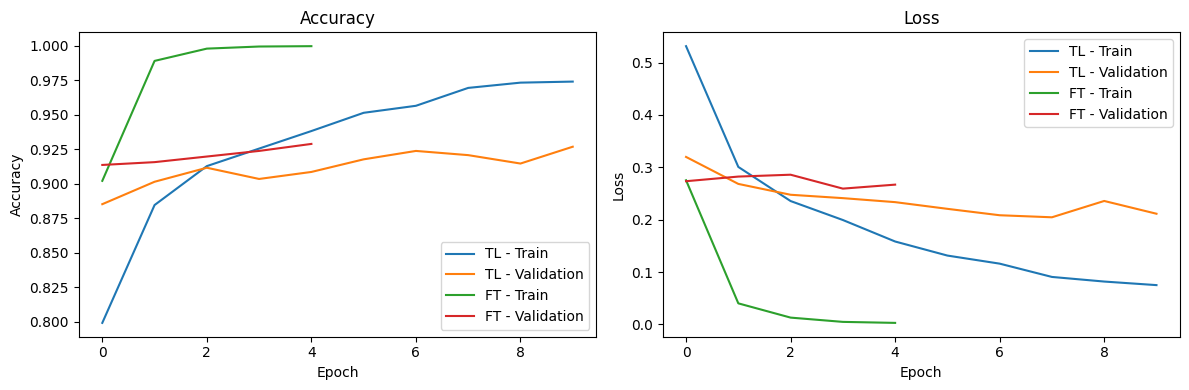

47/47 ━━━━━━━━━━━━━━━━━━━━ 5s 115ms/step - accuracy: 0.9198 - loss: 0.2196
Résultats -> Loss: 0.2196 | Accuracy: 0.9198 | F1-score: 0.9151


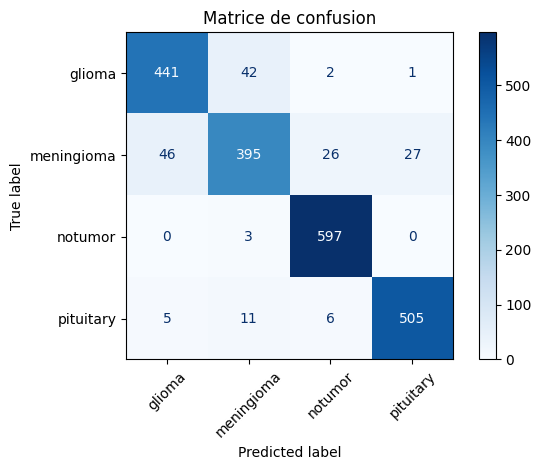

In [ ]:
build_transfer_model(
    base_model=MobileNetV2,
    normalize_collback=preprocess_input,
    x_train=X_train,
    y_train = y_train,
    x_val = X_val,
    y_val = y_val,
    x_test = X_test,
    y_test = y_test
)